<a href="https://colab.research.google.com/github/RoshanMR099/credit-risk-analytics/blob/main/credit-scorecard/uci_credit_default.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Default Model: Probability of Default (PD) Scorecard

**Data:** Default of Credit Card Clients, Taiwan, April to September 2005 (UCI Machine Learning Repository, id 350; Yeh and Lien, 2009). 30,000 clients, 23 features.

**Goal:** estimate each client's probability of default next month, check how well the model separates defaulters from non-defaulters, and turn the PD into a simple expected loss and a cut-off strategy.

**Note:** Taiwan consumer card data, used here to demonstrate the credit-risk modelling method.

## 1. Load and clean the data

In [ ]:
!pip install -q ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Taiwan credit card default data, UCI repository (id=350), April-September 2005
ds = fetch_ucirepo(id=350)
X = ds.data.features.copy()
y = ds.data.targets.copy()

# Suffix 1 = most recent month (September), suffix 6 = oldest month (April)
# PAY_n = repayment status, BILL_AMTn = bill amount, PAY_AMTn = amount paid
X.columns = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
             + [f"PAY_{i}" for i in range(1, 7)]
             + [f"BILL_AMT{i}" for i in range(1, 7)]
             + [f"PAY_AMT{i}" for i in range(1, 7)])
y.columns = ["default"]

# Undocumented codes are merged into the "others" category
X["EDUCATION"] = X["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
X["MARRIAGE"] = X["MARRIAGE"].replace({0: 3})

print(X.shape, y.shape)
print("Default rate:", y["default"].mean())
print("Missing values:", X.isnull().sum().sum())
X.head()

(30000, 23) (30000, 1)
Default rate: 0.2212
Missing values: 0


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


## 2. Prepare features, split, and fit the logistic regression

- SEX is excluded: lenders generally should not use gender in credit decisions.
- EDUCATION and MARRIAGE are categories, so each gets 0/1 columns (one-hot encoding).
- PAY_1, PAY_2 and PAY_3 (the three most recent repayment statuses) are grouped into categories (paid or unused, revolving, 1, 2, 3+ months late) instead of being treated as a straight numeric scale.
- 80/20 train/test split, stratified so both parts keep the same default rate.
- Features are scaled inside a pipeline so the scaler learns from the training data only.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X2 = X.copy()
# Treat the three most recent repayment statuses as categories instead of numbers:
# paid in full or unused, revolving, 1 month late, 2 months late, 3+ months late
for c in ["PAY_1", "PAY_2", "PAY_3"]:
    X2[c] = pd.cut(X2[c], bins=[-3, -1, 0, 1, 2, 10],
                   labels=["paid_or_unused", "revolving", "late_1", "late_2", "late_3plus"])

features = X2.drop(columns=["SEX"])
features = pd.get_dummies(features, columns=["EDUCATION", "MARRIAGE", "PAY_1", "PAY_2", "PAY_3"],
                          drop_first=True, dtype=int)
target = y["default"]

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, stratify=target, random_state=42)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

# Coefficients are per one-standard-deviation change in each feature
pd.Series(model.named_steps["logisticregression"].coef_[0],
          index=features.columns).sort_values()

,0
PAY_1_revolving,-0.355826
LIMIT_BAL,-0.271460
PAY_AMT1,-0.185132
PAY_AMT2,-0.178682
EDUCATION_4,-0.141375
PAY_3_revolving,-0.064558
MARRIAGE_2,-0.062570
EDUCATION_3,-0.044011
PAY_AMT6,-0.043211
BILL_AMT6,-0.040395


## 3. Evaluate the model on the test set

- **AUC:** chance the model ranks a random defaulter above a random non-defaulter (0.5 = coin flip, 1 = perfect).
- **Gini** = 2 x AUC - 1.
- **KS:** largest gap between the cumulative distributions of defaulters and non-defaulters.
- **Decile table:** clients ranked by predicted PD; the default rate should fall from the riskiest group (1) to the safest (10).

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve

pred_pd = model.predict_proba(X_test)[:, 1]   # predicted probability of default (PD)

auc = roc_auc_score(y_test, pred_pd)
gini = 2 * auc - 1
fpr, tpr, _ = roc_curve(y_test, pred_pd)
ks = (tpr - fpr).max()
print(f"AUC: {auc:.3f}   Gini: {gini:.3f}   KS: {ks:.3f}")

# Decile table: group 1 = highest-risk 10% of clients
results = pd.DataFrame({"pred_pd": pred_pd, "default": y_test.values})
results["risk_group"] = 10 - pd.qcut(results["pred_pd"], 10, labels=False)
decile_table = (results.groupby("risk_group")
                .agg(clients=("default", "size"), defaults=("default", "sum"),
                     avg_pred_pd=("pred_pd", "mean"), default_rate=("default", "mean"))
                .sort_index())
decile_table

AUC: 0.751   Gini: 0.501   KS: 0.385


,clients,defaults,avg_pred_pd,default_rate
risk_group,,,,
1,600,412,0.718047,0.686667
2,600,234,0.399155,0.390000
3,600,143,0.225115,0.238333
4,600,113,0.175632,0.188333
5,600,94,0.155619,0.156667
6,600,90,0.142571,0.150000
7,600,73,0.130881,0.121667
8,600,85,0.116916,0.141667
9,600,49,0.098212,0.081667


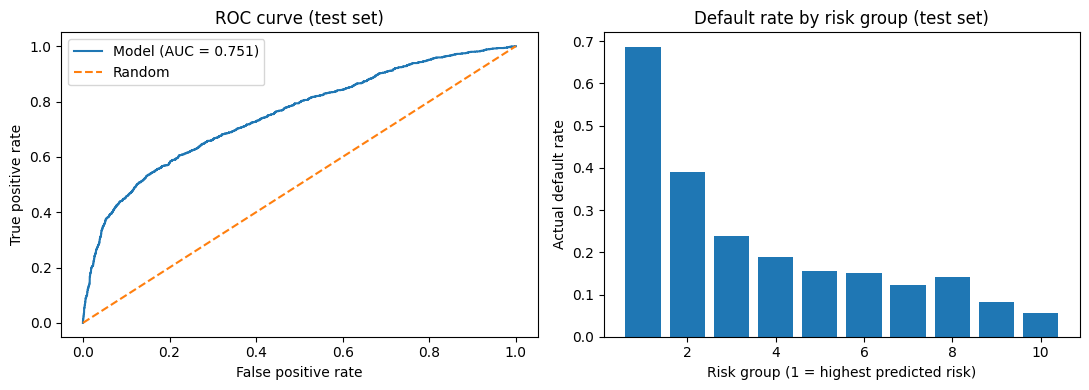

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
ax[0].plot([0, 1], [0, 1], "--", label="Random")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve (test set)")
ax[0].legend()

ax[1].bar(decile_table.index, decile_table["default_rate"])
ax[1].set_xlabel("Risk group (1 = highest predicted risk)")
ax[1].set_ylabel("Actual default rate")
ax[1].set_title("Default rate by risk group (test set)")

plt.tight_layout()
plt.show()

### Stability check: 5-fold cross-validation

The test-set result above comes from one split. Cross-validation refits the model on five different splits and reports the AUC of each, to check the result is not a one-split accident.

In [ ]:
from sklearn.model_selection import cross_val_score

cv_auc = cross_val_score(model, features, target, cv=5, scoring="roc_auc")
print("AUC by fold:", cv_auc.round(3))
print(f"Mean AUC: {cv_auc.mean():.3f}   Std: {cv_auc.std():.3f}")

AUC by fold: [0.745 0.742 0.771 0.783 0.767]
Mean AUC: 0.761   Std: 0.016


## 4. Expected loss: PD x EAD x LGD

- **PD** comes from the model.
- **EAD** (exposure at default) is approximated by the latest bill amount (negative balances set to 0).
- **LGD** (loss given default) is an **assumption** of 45%, because this dataset has no recovery information.
- Amounts are in New Taiwan dollars, as in the data.

In [ ]:
LGD = 0.45   # assumption: no recovery data in this dataset
results["ead"] = X_test["BILL_AMT1"].clip(lower=0).values
results["expected_loss"] = results["pred_pd"] * results["ead"] * LGD
results["actual_loss"] = results["default"] * results["ead"] * LGD

print(f"Total expected loss: {results['expected_loss'].sum():,.0f}")
print(f"Total actual loss:   {results['actual_loss'].sum():,.0f}")

Total expected loss: 30,014,435
Total actual loss:   30,268,341


## 5. Cut-off strategy

If the lender approves only clients whose predicted PD is below a cut-off, what share of clients is approved, and what is the default rate among them? A lower cut-off means fewer approvals and lower losses.

In [ ]:
rows = []
for cutoff in [0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
    approved = results["pred_pd"] < cutoff
    rows.append({
        "cutoff_pd": cutoff,
        "approval_rate": approved.mean(),
        "default_rate_among_approved": results.loc[approved, "default"].mean(),
    })
cutoff_table = pd.DataFrame(rows)

# Save tables so they can be opened in Excel (for example, to build a pivot table)
decile_table.to_csv("decile_table.csv")
cutoff_table.to_csv("cutoff_table.csv", index=False)

cutoff_table

,cutoff_pd,approval_rate,default_rate_among_approved
0,0.10,0.153167,0.059848
1,0.15,0.511833,0.112016
2,0.20,0.713000,0.129032
3,0.30,0.821667,0.146653
4,0.40,0.860000,0.154651
5,0.50,0.875000,0.157524


## 6. Results at a glance

| Item | Result |
|---|---|
| Data | 30,000 Taiwan card clients, 22.1% default rate next month |
| Model | Logistic regression PD scorecard (gender excluded, three most recent repayment statuses as categories) |
| Test set (6,000 clients) | AUC 0.751, Gini 0.501, KS 0.385 |
| 5-fold cross-validation | Mean AUC 0.761 (std 0.016) |
| Riskiest 10% of clients | 71.8% predicted default rate vs 68.7% actual |
| Safest 10% of clients | 5.8% predicted vs 5.7% actual |
| Strongest risk drivers | Latest repayment status: 2 months late (+0.49), 1 month late (+0.19), 3+ months late (+0.18) |
| Strongest protective factors | Revolving latest status (-0.36), higher credit limit (-0.27), larger latest payment (-0.19) |
| Expected loss (45% LGD assumed) | 30.0M vs 30.3M actual (NTD) |
| Cut-off at PD below 15% | Approves 51.2% of clients at an 11.2% default rate, against 22.1% overall |
| Cut-off at PD below 10% | Approves 15.3% of clients at a 6.0% default rate |

**What the project shows**

- The most recent repayment status is the strongest signal of default, and two months late is the riskiest.
- The model ranks clients well (AUC 0.75), and its predicted default rates are within about 3 percentage points of the actual rates in every risk group.
- A PD cut-off of 15% approves about half of the clients at roughly half the overall default rate.